# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
from pathlib import Path

import pandas as pd

brut = pd.read_csv(Path("donnees") / "consommation_brut.csv")

print("Forme :", brut.shape)
print("\nTypes :")
print(brut.dtypes)
print("\nValeurs manquantes :")
print(brut.isna().sum())
print("\nLignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Écritures différentes :", brut["quartier"].nunique())

Écritures différentes : 43


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
kwh_numerique = pd.to_numeric(brut["kwh"], errors="coerce")
valeurs_non_convertibles = brut.loc[
    brut["kwh"].notna() & kwh_numerique.isna(), "kwh"
]

print("Valeurs non convertibles :")
print(valeurs_non_convertibles.unique())

Valeurs non convertibles :
<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = pd.to_numeric(
    propre["kwh"].str.replace("kWh", "", regex=False).str.replace(" ", "", regex=False),
    errors="coerce",
)

print("Valeurs manquantes dans kwh :", propre["kwh"].isna().sum())

Valeurs manquantes dans kwh : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv(Path("donnees") / "quartiers.csv")
noms_officiels = dict(
    zip(quartiers["quartier"].str.lower(), quartiers["quartier"])
)
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms_officiels)

print("Nombre de quartiers :", propre["quartier"].nunique())
print("Noms non reconnus :", propre["quartier"].isna().sum())

Nombre de quartiers : 12
Noms non reconnus : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])

print("Forme après suppression :", propre.shape)

Forme après suppression : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane_quartier = propre.groupby("quartier")["kwh"].transform("median")
a_corriger = propre["kwh"] > 3 * mediane_quartier
print("Quartiers corrigés :", propre.loc[a_corriger, "quartier"].tolist())
propre.loc[a_corriger, "kwh"] = propre.loc[a_corriger, "kwh"] / 10

print("Maximum de kwh :", propre["kwh"].max())

Quartiers corrigés : ['Delmas 33', 'Delmas 75', 'Morne Calvaire', 'Rue 15']
Maximum de kwh : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv(Path("donnees") / "consommation.csv")
cles = ["mois", "quartier"]
colonnes = propre.columns.tolist()
index_propre = pd.MultiIndex.from_frame(propre[cles])
reference_alignee = (
    reference.set_index(cles)[["kwh", "heures_courant"]]
    .reindex(index_propre)
    .reset_index()
)[colonnes]
reference_alignee["kwh"] = reference_alignee["kwh"].astype(propre["kwh"].dtype)

print("Identique au fichier de référence :", propre.reset_index(drop=True).equals(
    reference_alignee.reset_index(drop=True)
))

Identique au fichier de référence : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
lignes_avant = len(propre)
avec_quartiers = propre.merge(
    quartiers, on="quartier", how="left", validate="many_to_one"
)
avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

print("Lignes avant la jointure :", lignes_avant)
print("Lignes après la jointure :", len(avec_quartiers))
print(
    "Bas-Peu-de-Chose, 2024-01 :",
    avec_quartiers.loc[
        (avec_quartiers["quartier"] == "Bas-Peu-de-Chose")
        & (avec_quartiers["mois"] == "2024-01"),
        "kwh_par_abonne",
    ].iloc[0],
)

Lignes avant la jointure : 279
Lignes après la jointure : 279
Bas-Peu-de-Chose, 2024-01 : 85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv(Path("donnees") / "meteo.csv")
lignes_avant = len(avec_quartiers)
avec_meteo = avec_quartiers.merge(
    meteo, on=["mois", "commune"], how="left", validate="many_to_one"
)

print("Lignes avant la jointure :", lignes_avant)
print("Lignes après la jointure :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes avant la jointure : 279
Lignes après la jointure : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
chemin_propre = Path("donnees") / "consommation_propre.csv"
avec_meteo.to_csv(chemin_propre, index=False)
consommation_propre = pd.read_csv(chemin_propre)

print("Forme du fichier propre :", consommation_propre.shape)

Forme du fichier propre : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
moyenne_par_type = avec_quartiers.groupby("type")["kwh_par_abonne"].mean().round(1)
classement_quartiers = (
    avec_quartiers.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .sort_values(ascending=False)
    .round(1)
)

print("Consommation moyenne par abonné selon le type :")
display(moyenne_par_type)
print("Classement des quartiers :")
display(classement_quartiers)

Consommation moyenne par abonné selon le type :


type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des quartiers :


quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64

**Ce qu'on en conclut :** Les quartiers commerciaux consomment en moyenne davantage par abonné (393,2 kWh) que les quartiers résidentiels (117,4 kWh). Centre-ville arrive en tête (468,7 kWh par abonné), suivi de Place Saint-Pierre (458,3) et de Delmas 33 (374,4).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Consommation totale par commune et par année (millions de kWh) :


annee,2024,2025
commune,,
Cap-Haïtien,4.59,5.62
Delmas,11.61,11.74
Port-au-Prince,10.09,10.31
Pétion-Ville,8.60,9.68


Hausse de 2024 à 2025 (%) :


commune
Cap-Haïtien       22.5
Pétion-Ville      12.6
Port-au-Prince     2.3
Delmas             1.1
dtype: float64

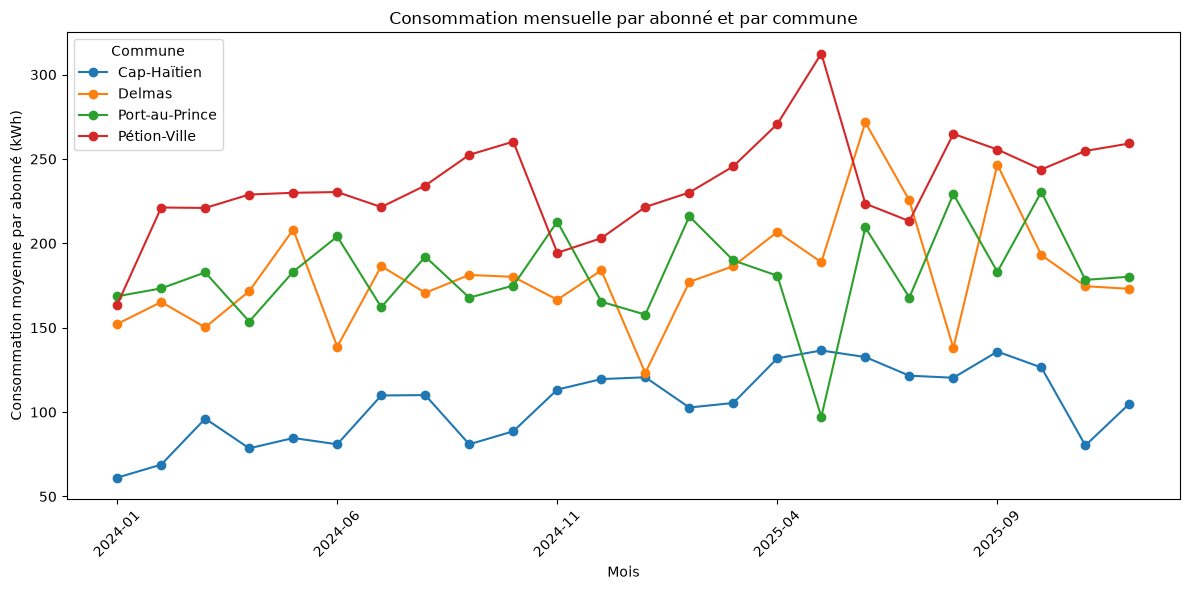

In [13]:
import matplotlib.pyplot as plt

consommation_par_commune_annee = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
)
hausse_pourcent = (
    (consommation_par_commune_annee[2025] / consommation_par_commune_annee[2024] - 1)
    * 100
).sort_values(ascending=False)
totaux_millions = (consommation_par_commune_annee / 1_000_000).round(2)

print("Consommation totale par commune et par année (millions de kWh) :")
display(totaux_millions)
print("Hausse de 2024 à 2025 (%) :")
display(hausse_pourcent.round(1))

consommation_mensuelle_par_abonne = (
    avec_meteo.groupby(["mois", "commune"])
    .agg(kwh_total=("kwh", "sum"), abonnes=("abonnes", "sum"))
    .assign(kwh_par_abonne=lambda df: df["kwh_total"] / df["abonnes"])
    .reset_index()
)
courbe = consommation_mensuelle_par_abonne.pivot(
    index="mois", columns="commune", values="kwh_par_abonne"
)
courbe.plot(figsize=(12, 6), marker="o")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne par abonné (kWh)")
plt.title("Consommation mensuelle par abonné et par commune")
plt.xticks(rotation=45)
plt.legend(title="Commune")
plt.tight_layout()

**Ce qu'on en conclut :** La consommation totale augmente le plus à Cap-Haïtien, de 4,59 à 5,62 millions de kWh entre 2024 et 2025, soit +22,4 %. Delmas connaît la plus faible hausse (+1,1 %). Les courbes mensuelles permettent aussi de comparer l'évolution de la consommation par abonné dans les quatre communes.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


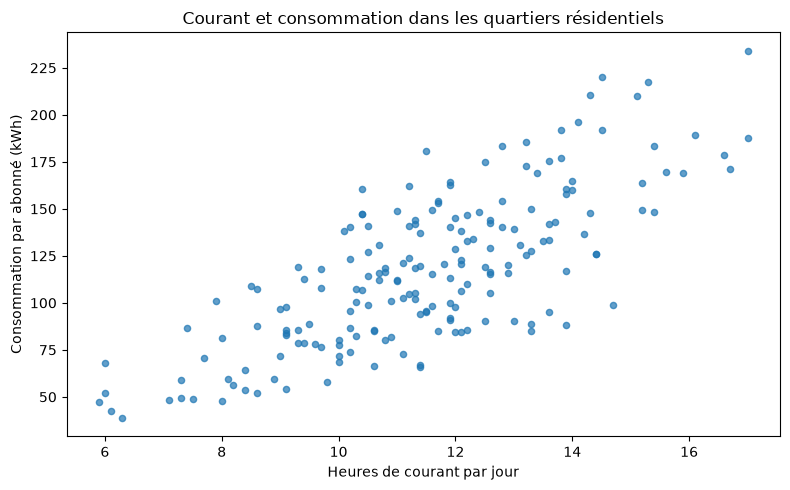

In [14]:
residentiel = avec_meteo.loc[avec_meteo["type"] == "Résidentiel"].copy()

residentiel.plot.scatter(
    x="heures_courant",
    y="kwh_par_abonne",
    figsize=(8, 5),
    alpha=0.7,
)
plt.xlabel("Heures de courant par jour")
plt.ylabel("Consommation par abonné (kWh)")
plt.title("Courant et consommation dans les quartiers résidentiels")
plt.tight_layout()

correlation_heures = residentiel["kwh_par_abonne"].corr(
    residentiel["heures_courant"]
)
correlation_temperature = residentiel["kwh_par_abonne"].corr(
    residentiel["temperature_c"]
)
print("Corrélation avec les heures de courant :", round(correlation_heures, 2))
print("Corrélation avec la température :", round(correlation_temperature, 2))

**Ce qu'on en conclut :** Dans les quartiers résidentiels, la consommation par abonné est plus fortement associée aux heures de courant (corrélation de 0,76) qu'à la température (−0,15). Ces corrélations décrivent une association dans les données, mais ne prouvent pas que les heures de courant ou la température causent les variations de consommation.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Heures de courant par commune :


,mediane,Q1,Q3
commune,,,
Cap-Haïtien,10.0,8.3,11.7
Delmas,11.9,10.1,13.0
Port-au-Prince,11.6,10.7,13.1
Pétion-Ville,11.6,10.4,13.0


Relevés de 2025 avec moins de 8 heures : 3


,mois,quartier,heures_courant
81,2025-01,Delmas 33,7.4
227,2025-08,Carénage,7.3
253,2025-11,Rue 15,5.9


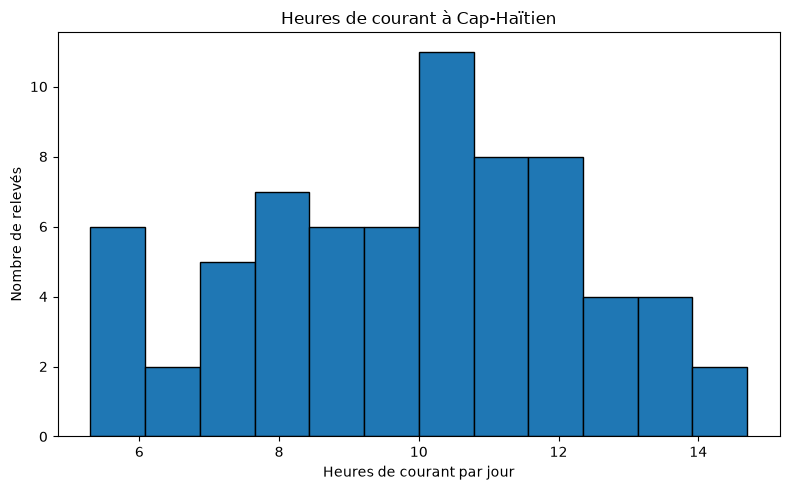

In [15]:
heures_par_commune = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda serie: serie.quantile(0.25),
    Q3=lambda serie: serie.quantile(0.75),
)
print("Heures de courant par commune :")
display(heures_par_commune.round(1))

cap_haitien = avec_meteo.loc[avec_meteo["commune"] == "Cap-Haïtien", "heures_courant"]
cap_haitien.plot.hist(bins=12, figsize=(8, 5), edgecolor="black")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.title("Heures de courant à Cap-Haïtien")
plt.tight_layout()

moins_de_huit_heures = avec_meteo.loc[
    (avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8),
    ["mois", "quartier", "heures_courant"],
]
print("Relevés de 2025 avec moins de 8 heures :", len(moins_de_huit_heures))
display(moins_de_huit_heures)

**Ce qu'on en conclut :** Cap-Haïtien a la médiane la plus basse, avec 10,0 heures de courant par jour, contre 11,6 à 11,9 heures dans les autres communes. En 2025, trois relevés passent sous 8 heures : Carénage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
plus_grosses_consommations = avec_meteo.nlargest(3, "kwh")[[
    "mois", "quartier", "type", "kwh"
]]
display(plus_grosses_consommations)

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :** Les trois plus fortes consommations relevées sont celles de Delmas 33 en juillet 2025 (742 780 kWh), du Centre-ville en novembre 2024 (597 730 kWh) et de Delmas 33 en septembre 2025 (591 420 kWh). Ces pics méritent d'être examinés dans leur contexte avant d'en tirer des conclusions.

## 9. Conclusion

Dans les quartiers résidentiels, la consommation par abonné est davantage associée aux heures de courant (corrélation de 0,76) qu'à la température (−0,15). Les données suggèrent donc un lien plus fort avec la disponibilité du courant qu'avec la chaleur. Une corrélation ne prouve toutefois pas une relation de cause à effet et ne permet pas, à elle seule, d'expliquer les variations observées.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.